<a href="https://colab.research.google.com/github/halynazhabchyk/stroke_prediction/blob/main/stroke_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завантаження даних

In [ ]:
# завантажуємо файл з даними
import kagglehub


path = kagglehub.dataset_download("afridirahman/brain-stroke-ct-image-dataset")

print("Path to dataset files:", path)

100%|██████████| 60.4M/60.4M [00:00<00:00, 94.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/afridirahman/brain-stroke-ct-image-dataset/versions/1


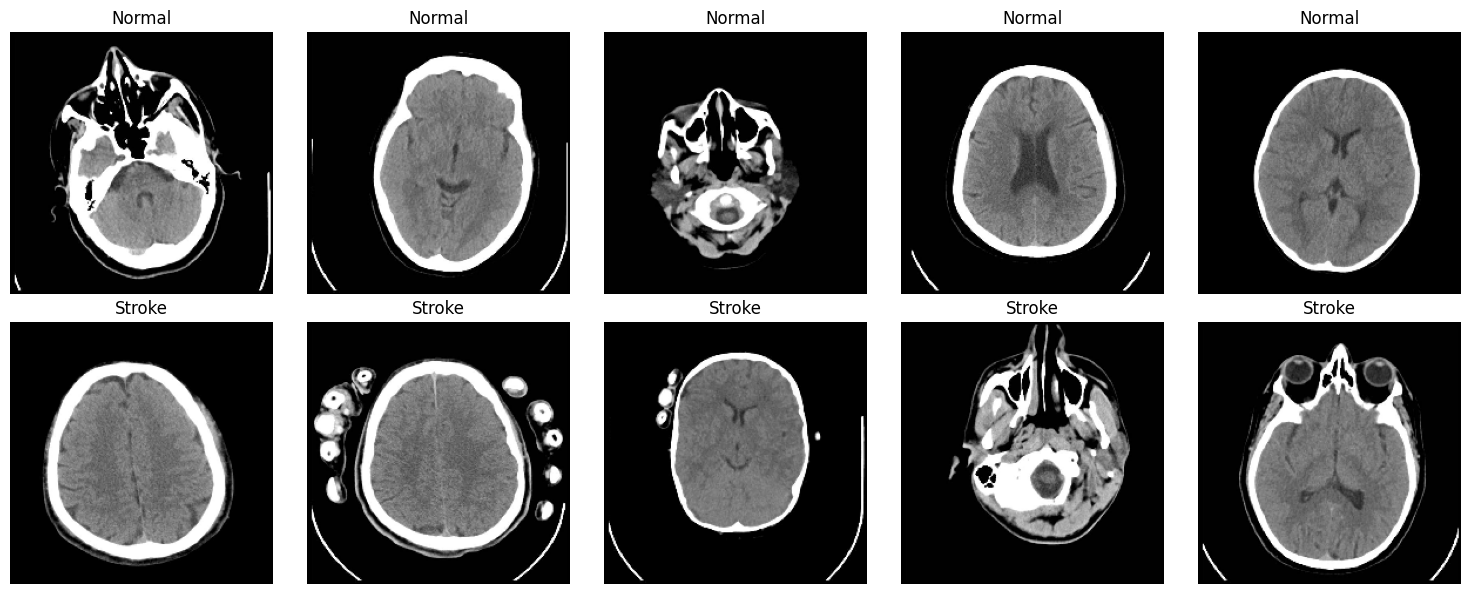

In [ ]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Шляхи до папок із зображеннями
normal_path = "/root/.cache/kagglehub/datasets/afridirahman/brain-stroke-ct-image-dataset/versions/1/Brain_Data_Organised/Normal"
stroke_path = "/root/.cache/kagglehub/datasets/afridirahman/brain-stroke-ct-image-dataset/versions/1/Brain_Data_Organised/Stroke"

# Перевірка існування папок
if not os.path.exists(normal_path):
    print(f"Path not found: {normal_path}")
if not os.path.exists(stroke_path):
    print(f"Path not found: {stroke_path}")

def load_images_and_labels(normal_path, stroke_path, num_images=5):
    normal_images = glob.glob(os.path.join(normal_path, "*.jpg"))
    stroke_images = glob.glob(os.path.join(stroke_path, "*.jpg"))

    data = []
    labels = []
    for img_path in normal_images:
        img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))  # Resize to 224x224
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        data.append(img_array)
        labels.append(0)  # 0 - Normal

    for img_path in stroke_images:
        img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))  # Resize to 224x224
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        data.append(img_array)
        labels.append(1)  # 1 - Stroke

    # Перетворення даних на масиви NumPy
    data = np.array(data)
    labels = np.array(labels)

    # Візуалізація кількох зображень
    fig, axes = plt.subplots(2, num_images, figsize=(15, 6))  # Створення сітки для зображень (2 ряди, по num_images зображень в кожному)

    # Вибір зображень для кожної категорії
    normal_images = data[labels == 0]  # Зображення нормальні
    stroke_images = data[labels == 1]  # Зображення з інсультом

    for i in range(num_images):
        # Виведення зображень для категорії "Normal"
        axes[0, i].imshow(normal_images[i].astype('uint8'))
        axes[0, i].axis('off')
        axes[0, i].set_title("Normal")

        # Виведення зображень для категорії "Stroke"
        axes[1, i].imshow(stroke_images[i].astype('uint8'))
        axes[1, i].axis('off')
        axes[1, i].set_title("Stroke")

    plt.tight_layout()
    plt.show()

    return data, labels

# Завантаження даних та виведення зображень
data, labels = load_images_and_labels(normal_path, stroke_path)


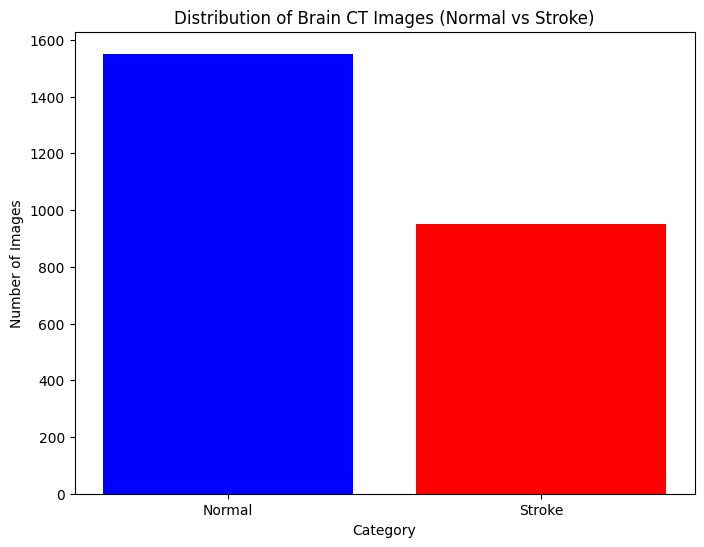

In [ ]:
# Підготовка даних для гістограми
categories = ['Normal', 'Stroke']
counts = [len(normal_images),len(stroke_images)]

# Побудова гістограми
plt.figure(figsize=(8,6))
plt.bar(categories, counts, color=['blue', 'red'])
plt.xlabel('Category')
plt.ylabel('Number of Images')
plt.title('Distribution of Brain CT Images (Normal vs Stroke)')
plt.show()

In [ ]:
# Нормалізація даних
data = data / 255.0
x_train, x_test, y_train, y_test = train_test_split(data, labels, test_size=0.10, shuffle=True)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)


(2250, 224, 224, 3)
(251, 224, 224, 3)
(2250,)
(251,)


In [ ]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),strides=1,padding="valid",activation="relu", input_shape=(224,224,3)))
model.add(MaxPooling2D(pool_size=2))

model.add(Conv2D(64,kernel_size=(3,3),strides=1,padding="valid",activation="relu"))
model.add(MaxPooling2D(pool_size=2))

model.add(Conv2D(128,kernel_size=(3,3),strides=1,padding="valid",activation="relu"))
model.add(MaxPooling2D(pool_size=2))

model.add(Flatten())
model.add(Dense(256, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer="adam",loss="binary_crossentropy",
             metrics=["accuracy"])



In [ ]:
history = model.fit(x_train,y_train,batch_size=32,
         epochs=10, validation_data=(x_test,y_test))

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 265s 4s/step - accuracy: 0.6355 - loss: 0.7485 - val_accuracy: 0.7689 - val_loss: 0.4298
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 319s 4s/step - accuracy: 0.8715 - loss: 0.3089 - val_accuracy: 0.9283 - val_loss: 0.1537
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 259s 4s/step - accuracy: 0.9675 - loss: 0.0917 - val_accuracy: 0.9641 - val_loss: 0.0946
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 263s 4s/step - accuracy: 0.9826 - loss: 0.0429 - val_accuracy: 0.9880 - val_loss: 0.0422
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 259s 4s/step - accuracy: 0.9894 - loss: 0.0217 - val_accuracy: 0.9880 - val_loss: 0.0493
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 260s 4s/step - accuracy: 0.9945 - loss: 0.0100 - val_accuracy: 0.9880 - val_loss: 0.0426
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 264s 4s/step - accuracy: 0.9971 - loss: 0.0074 - val_accuracy: 0.9920 - val_loss: 0.0313
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 263s 4s/step - accuracy: 0.9986 - loss: 0.0043 - val_accuracy: 0.9681 - v

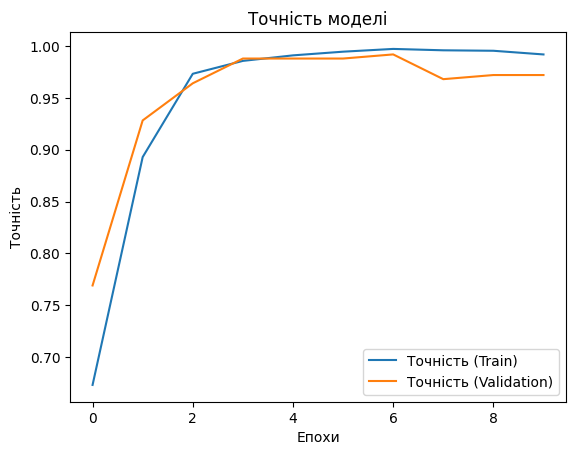

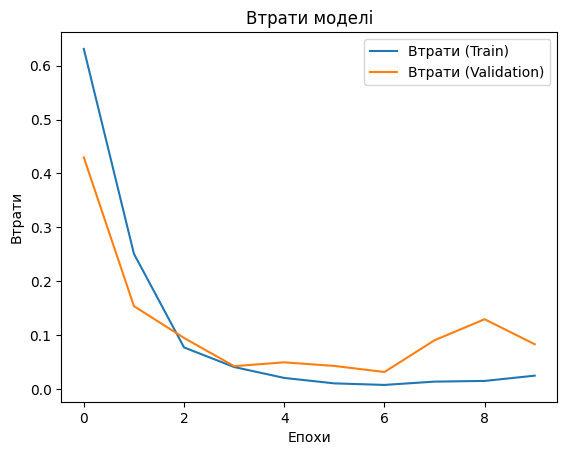

In [ ]:
import matplotlib.pyplot as plt



# Графік точності
plt.plot(history.history['accuracy'], label='Точність (Train)')
plt.plot(history.history['val_accuracy'], label='Точність (Validation)')
plt.title('Точність моделі')
plt.xlabel('Епохи')
plt.ylabel('Точність')
plt.legend()
plt.show()

# Графік втрат
plt.plot(history.history['loss'], label='Втрати (Train)')
plt.plot(history.history['val_loss'], label='Втрати (Validation)')
plt.title('Втрати моделі')
plt.xlabel('Епохи')
plt.ylabel('Втрати')
plt.legend()
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error

# Оцінка моделі на тестових даних
y_pred = model.predict(x_test)
y_pred = (y_pred > 0.5).astype("int32")  # Перетворення ймовірностей на класи (0 або 1)

# Обчислення точності (Accuracy)
accuracy = accuracy_score(y_test, y_pred)

# Обчислення пресижн (Precision)
precision = precision_score(y_test, y_pred)

# Обчислення відгуку (Recall)
recall = recall_score(y_test, y_pred)

# Обчислення F1-міри (F1 Score)
f1 = f1_score(y_test, y_pred)

# Обчислення похибки (Error)
error = 1 - accuracy

# Виведення результатів
print(f"Точність (Accuracy): {accuracy:.4f}")
print(f"Пресижн (Precision): {precision:.4f}")
print(f"Відгук (Recall): {recall:.4f}")
print(f"F1-міра (F1 Score): {f1:.4f}")
print(f"Похибка (Error): {error:.4f}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step
Точність (Accuracy): 0.9681
Пресижн (Precision): 0.9340
Відгук (Recall): 0.9900
F1-міра (F1 Score): 0.9612
Похибка (Error): 0.0319
